In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [4]:
# DETECTION
BASIC_PATH_DETECTION = "../output_5runs/detection/temporal=false-retriever=false-summarizer=false/ModernBERT-base/seed_42/bs8_lr3e-5_ep5_seed42/predict_results.txt"
BEST_RAG_PATH_DETECTION = "../output_5runs/detection/temporal=true-retriever=ddore14-sentence-roosebert-search=hybrid-rerank=cross-encoder-ms-marco-minilm-l-6-v2-query=relations_labeled-summarizer=false/ModernBERT-base/seed_42/bs8_lr5e-5_ep5_seed42/predict_results.txt"

# CLASSIFICATION
BASIC_PATH_CLASSIFICATION = "../output_5runs/classification/temporal=false-retriever=false-summarizer=false//predict_results.txt"
BEST_RAG_PATH_CLASSIFICATION = "../output_5runs/classification/ /predict_results.txt"

In [5]:
def read_predictions(path: str):
    predictions = []
    with open(path) as f:
        for row in f.readlines()[1:]:
            _, prediction, gold = row.split("\t")
            predictions.append(
                {
                    'prediction': prediction.strip(),
                    'gold': gold.strip()
                }
            )
    return pd.DataFrame(predictions)

In [6]:
def error_analysis(path: str, title: str, filename: str, labels: list):
    preds = read_predictions(path)
    print(preds.head())

    print(f"=================== Classification Report {title} ===================")
    print(classification_report(preds['gold'].tolist(), preds['prediction'].tolist()))

    cf_matrix = confusion_matrix(preds['gold'].tolist(), preds['prediction'].tolist())
    sns.heatmap(cf_matrix / np.sum(cf_matrix),
                annot=True, fmt='.2%', cmap='Blues', annot_kws={"size": 20},
                xticklabels=labels, yticklabels=labels)
    plt.title(f"Confusion Matrix\n{title}", weight='bold', fontsize=24)
    plt.xticks(size=20)
    plt.yticks(size=20)
    plt.savefig(f"{filename}.pdf", dpi=1200)
    plt.show()

  prediction       gold
0    Fallacy    Fallacy
1    Fallacy    Fallacy
2  NoFallacy  NoFallacy
3  NoFallacy    Fallacy
4    Fallacy    Fallacy
=================== Classification Report ModernBERT with BASIC Configuration ===================
              precision    recall  f1-score   support

     Fallacy       0.75      0.82      0.79       163
   NoFallacy       0.81      0.73      0.77       164

    accuracy                           0.78       327
   macro avg       0.78      0.78      0.78       327
weighted avg       0.78      0.78      0.78       327



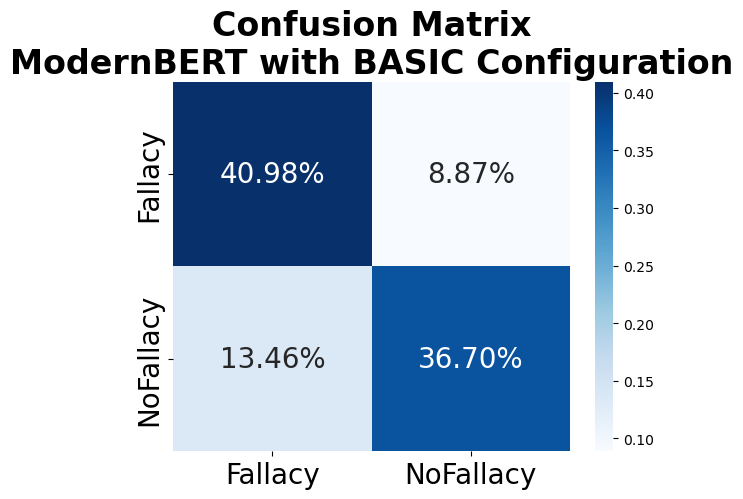

In [7]:
error_analysis(path=BASIC_PATH_DETECTION,
               title="ModernBERT with BASIC Configuration",
               filename="cm_detection_basic",
               labels=['Fallacy', 'NoFallacy'])

  prediction       gold
0    Fallacy    Fallacy
1    Fallacy    Fallacy
2  NoFallacy  NoFallacy
3    Fallacy    Fallacy
4    Fallacy    Fallacy
=================== Classification Report ModernBERT with BEST RAG Configuration ===================
              precision    recall  f1-score   support

     Fallacy       0.85      0.92      0.88       163
   NoFallacy       0.91      0.84      0.87       164

    accuracy                           0.88       327
   macro avg       0.88      0.88      0.88       327
weighted avg       0.88      0.88      0.88       327



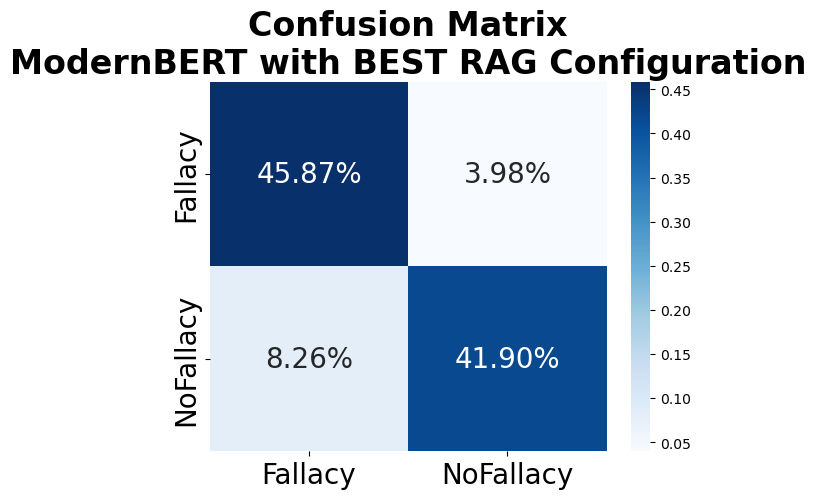

In [8]:
error_analysis(path=BEST_RAG_PATH_DETECTION,
               title="ModernBERT with BEST RAG Configuration",
               filename="cm_detection_best_rag",
               labels=['Fallacy', 'NoFallacy'])

In [ ]:
error_analysis(path=BASIC_PATH_CLASSIFICATION,
               title="ModernBERT with BASIC Configuration",
               filename="cm_classification_basic",
               labels=[])

In [ ]:
error_analysis(path=BEST_RAG_PATH_CLASSIFICATION,
               title="ModernBERT with BEST RAG Configuration",
               filename="cm_classification_best_rag",
               labels=[])